<h1><b>Pós-Graduação em Inteligência Artificial Aplicada</b></h1>

<h2>Unidade Curricular: Aprendizado de Máquina</h2>
<h2>Trabalho análise exploratória de dados (EDA)</h2>

<h2>Alunos:</h2>

<ul>
  <li>Adair</li>
  <li>Jones</li>
  <li>Miriam Stal</li>
  <li>Nathan Hoepers</li>
  <li>Vera Azevedo</li>
</ul>

# **Contexto de Negócio**

Somos consultores de dados contratados pelo departamento de crédito consignado com garantia de imóvel (home equity) de uma instituição financeira. A área de concessão de crédito quer automatizar parte da decisão de aprovação de empréstimos, seguindo as recomendações do Equal Credit Opportunity Act — ou seja, precisa de um modelo estatisticamente sólido e explicável, não uma “caixa-preta”.

Antes de qualquer modelagem (que faremos em aulas futuras), a diretoria de risco pediu uma análise exploratória completa:
1. Entender quem são os tomadores de empréstimo;
2. Onde estão os problemas de qualidade dos dados;
3. Quais variáveis parecem mais associadas à inadimplência.


**Perguntas de negócio:**

1. Quais características dos tomadores de empréstimo estão associadas a um maior risco de inadimplência;
2. A base de dados está em condições de sustentar essa análise com confiança?

**Base de dados**

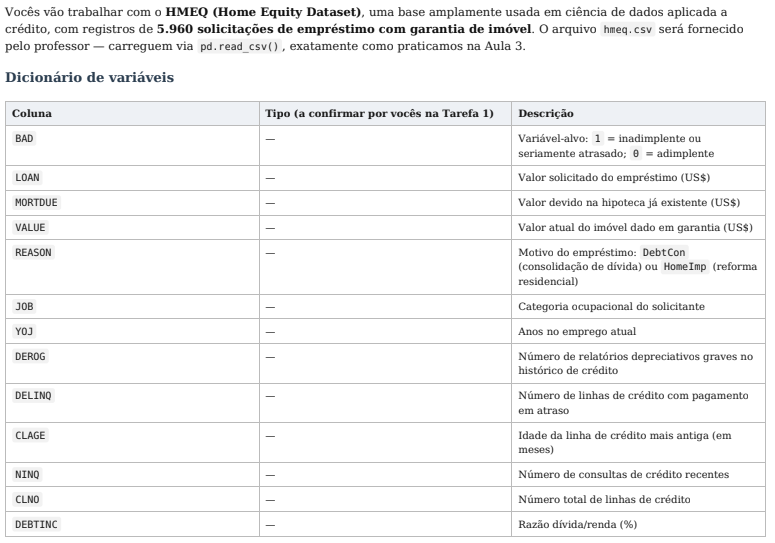

# Imports e dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Bibliotecas carregadas com sucesso.")


Bibliotecas carregadas com sucesso.


In [2]:
# Arquivo de dados compartilhado com acesso a qualquer pessoa com link
file_id = "1UIad_ImBiggbCpFPQhCIXURiS9NjAZPH"
url = f"https://drive.google.com/uc?id={file_id}"
df_original = pd.read_csv(url)

df = df_original.copy()

# Funções auxiliares

In [3]:
def renomear_colunas_hmeq(df, avisar_ausentes=True):
    """
    Renomeia as colunas do dataset HMEQ do inglês para português,
    seguindo o dicionário de/para padrão.
    """
    de_para = {
        'BAD': 'target_inadimplencia',
        'LOAN': 'valor_emprestimo',
        'MORTDUE': 'valor_divida_hipoteca',
        'VALUE': 'valor_imovel',
        'REASON': 'motivo_emprestimo',
        'JOB': 'categoria_ocupacional',
        'YOJ': 'anos_emprego_atual',
        'DEROG': 'qtd_registros_credito_negativos',
        'DELINQ': 'qtd_linhas_credito_atrasadas',
        'CLAGE': 'idade_linha_credito_mais_antiga_meses',
        'NINQ': 'qtd_consultas_credito_recentes',
        'CLNO': 'qtd_linhas_credito',
        'DEBTINC': 'percentual_divida_renda'
    }

    if avisar_ausentes:
        ausentes = set(de_para.keys()) - set(df.columns)
        if ausentes:
            print(f"Aviso: colunas não encontradas no DataFrame: {ausentes}")

    return df.rename(columns=de_para)


def imputar_percentual_divida_renda(df_entrada, n_neighbors=5):
    """
    Imputa valores ausentes em 'percentual_divida_renda' usando KNNImputer,
    considerando as demais colunas numéricas e categóricas do dataset HMEQ.
    """

    df_saida = df_entrada.copy()  # não altera o df original passado como argumento

    # 1. Definir colunas a usar (exclui target e qtd_nulos_linha)
    colunas_numericas = [
        "valor_emprestimo",
        "valor_divida_hipoteca",
        "valor_imovel",
        "anos_emprego_atual",
        "qtd_registros_credito_negativos",
        "qtd_linhas_credito_atrasadas",
        "idade_linha_credito_mais_antiga_meses",
        "qtd_consultas_credito_recentes",
        "qtd_linhas_credito",
        "percentual_divida_renda"
    ]

    colunas_categoricas = [
        "motivo_emprestimo",
        "categoria_ocupacional"
    ]

    # 2. Transformar categóricas em dummies
    df_dummies = pd.get_dummies(df_saida[colunas_categoricas], drop_first=True)

    # 3. Juntar numéricas + dummies
    df_para_imputar = pd.concat([df_saida[colunas_numericas], df_dummies], axis=1)

    # 4. Escalar os dados
    scaler = StandardScaler()
    df_scaled = pd.DataFrame(
        scaler.fit_transform(df_para_imputar),
        columns=df_para_imputar.columns,
        index=df_para_imputar.index
    )

    # 5. Rodar o KNNImputer
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df_imputado_scaled = pd.DataFrame(
        imputer.fit_transform(df_scaled),
        columns=df_para_imputar.columns,
        index=df_para_imputar.index
    )

    # 6. Reverter a escala
    df_imputado = pd.DataFrame(
        scaler.inverse_transform(df_imputado_scaled),
        columns=df_para_imputar.columns,
        index=df_para_imputar.index
    )

    # 7. Substituir apenas a coluna de interesse
    df_saida["percentual_divida_renda"] = df_imputado["percentual_divida_renda"]

    return df_saida


def taxa_faltante_por_grupo(df, coluna_grupo, coluna_alvo):
    taxa = df.groupby(coluna_grupo)[coluna_alvo].apply(
        lambda col: col.isnull().mean()
    ).round(4)
    return taxa


def skew_kurt(df, coluna):
    """
    Calcula e imprime skewness e kurtosis (excesso, fisher=True) de uma coluna numérica.
    """
    skew_val = stats.skew(df[coluna])
    kurt_val = stats.kurtosis(df[coluna])  # excesso de curtose (fisher=True, padrão)

    print(f"Skewness de {coluna}: {skew_val:.2f}")
    print(f"Kurtosis (excesso) de {coluna}: {kurt_val:.2f}")


def plot_dist_boxplot(df, coluna, bins=30, cor="steelblue"):
    """
    Plota histograma + KDE e boxplot de uma coluna numérica lado a lado.
    """
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Histograma + KDE
    sns.histplot(df[coluna], bins=bins, kde=True, ax=axes[0], color=cor)
    axes[0].set_title(f"Distribuição de {coluna} (histograma + KDE)")
    axes[0].set_xlabel(coluna)

    # Boxplot
    sns.boxplot(x=df[coluna], ax=axes[1], color=cor)
    axes[1].set_title(f"Boxplot de {coluna}")
    axes[1].set_xlabel(coluna)

    plt.tight_layout()
    plt.show()


def outliers_iqr(df, coluna):
    """
    Calcula limites de outliers pela regra do IQR (1.5x) para uma coluna numérica
    e retorna o subconjunto do DataFrame com os outliers.
    """
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]

    print(f"Q1 = {Q1:.1f} | Q3 = {Q3:.1f} | IQR = {IQR:.1f}")
    print(f"Limite inferior = {limite_inferior:.1f} | Limite superior = {limite_superior:.1f}")
    print(f"Quantidade de outliers pela regra do IQR: {len(outliers)}\n")

    return outliers


def outliers_zscore(df, coluna, limite=3):
    """
    Identifica outliers pelo critério do Z-Score (|Z| > limite) de uma coluna numérica.
    """
    z_scores = stats.zscore(df[coluna], nan_policy="omit")

    outliers = df[np.abs(z_scores) > limite]

    print(f"Quantidade de outliers pelo critério de Z-Score (|Z| > {limite}): {len(outliers)}")

    return outliers

# **Bloco 1 - Inspeção Estrutural**

**Tarefa 1:** Completem o dicionário de variáveis acima, classificando cada coluna em Qualitativa Nominal / Qualitativa Ordinal / Quantitativa Discreta / Quantitativa Contínua, com uma frase de justificativa para cada uma.

**Criado um DE x PARA para melhor entendimento das variáveis**

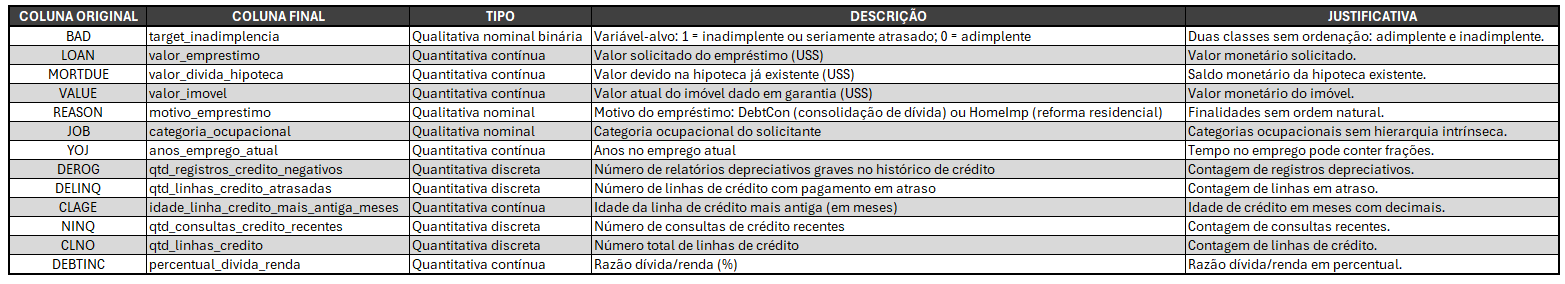

**Tarefa 2:** Façam a auditoria de formato ( shape , dtypes , info() , head() , tail() ) e verifiquem a coerência dos nomes de
colunas (padronizem se necessário).

In [4]:
print(f'Colunas do DF carregado: {df.columns}\n')
print(f'Possui: {df.shape[0]} linhas, {df.shape[1]} colunas.')

Colunas do DF carregado: Index(['BAD', 'LOAN', 'MORTDUE', 'VALUE', 'REASON', 'JOB', 'YOJ', 'DEROG',
       'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC'],
      dtype='object')

Possui: 5960 linhas, 13 colunas.


In [5]:
#Renomear colunas do DF para melhor entendimento das variáveis
df = renomear_colunas_hmeq(df)

print(f'Colunas renomeadas do DF: {df.columns}\n')

Colunas renomeadas do DF: Index(['target_inadimplencia', 'valor_emprestimo', 'valor_divida_hipoteca',
       'valor_imovel', 'motivo_emprestimo', 'categoria_ocupacional',
       'anos_emprego_atual', 'qtd_registros_credito_negativos',
       'qtd_linhas_credito_atrasadas', 'idade_linha_credito_mais_antiga_meses',
       'qtd_consultas_credito_recentes', 'qtd_linhas_credito',
       'percentual_divida_renda'],
      dtype='object')



In [6]:
df.dtypes

,0
target_inadimplencia,int64
valor_emprestimo,int64
valor_divida_hipoteca,float64
valor_imovel,float64
motivo_emprestimo,object
categoria_ocupacional,object
anos_emprego_atual,float64
qtd_registros_credito_negativos,float64
qtd_linhas_credito_atrasadas,float64
idade_linha_credito_mais_antiga_meses,float64


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   target_inadimplencia                   5960 non-null   int64  
 1   valor_emprestimo                       5960 non-null   int64  
 2   valor_divida_hipoteca                  5442 non-null   float64
 3   valor_imovel                           5848 non-null   float64
 4   motivo_emprestimo                      5708 non-null   object 
 5   categoria_ocupacional                  5681 non-null   object 
 6   anos_emprego_atual                     5445 non-null   float64
 7   qtd_registros_credito_negativos        5252 non-null   float64
 8   qtd_linhas_credito_atrasadas           5380 non-null   float64
 9   idade_linha_credito_mais_antiga_meses  5652 non-null   float64
 10  qtd_consultas_credito_recentes         5450 non-null   float64
 11  qtd_

In [8]:
df.head()

,target_inadimplencia,valor_emprestimo,valor_divida_hipoteca,valor_imovel,motivo_emprestimo,categoria_ocupacional,anos_emprego_atual,qtd_registros_credito_negativos,qtd_linhas_credito_atrasadas,idade_linha_credito_mais_antiga_meses,qtd_consultas_credito_recentes,qtd_linhas_credito,percentual_divida_renda
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN


In [9]:
df.tail()

,target_inadimplencia,valor_emprestimo,valor_divida_hipoteca,valor_imovel,motivo_emprestimo,categoria_ocupacional,anos_emprego_atual,qtd_registros_credito_negativos,qtd_linhas_credito_atrasadas,idade_linha_credito_mais_antiga_meses,qtd_consultas_credito_recentes,qtd_linhas_credito,percentual_divida_renda
5955,0,88900,57264.0,90185.0,DebtCon,Other,16.0,0.0,0.0,221.808718,0.0,16.0,36.112347
5956,0,89000,54576.0,92937.0,DebtCon,Other,16.0,0.0,0.0,208.692070,0.0,15.0,35.859971
5957,0,89200,54045.0,92924.0,DebtCon,Other,15.0,0.0,0.0,212.279697,0.0,15.0,35.556590
5958,0,89800,50370.0,91861.0,DebtCon,Other,14.0,0.0,0.0,213.892709,0.0,16.0,34.340882
5959,0,89900,48811.0,88934.0,DebtCon,Other,15.0,0.0,0.0,219.601002,0.0,16.0,34.571519


Em comparação com a tabela do dicionário, seguem as colunas que terão o tipo de dado ajustado:
  1. valor_emprestimo: Alterar para "float";
  2. qtd_registros_credito_negativos: Alterar para "int";
  3. qtd_linhas_credito_atrasadas: Alterar para "int";
  4. qtd_consultas_credito_recentes: Alterar para "int";
  5. qtd_linhas_credito: Alterar para "int";

In [10]:
# Alterando o tipo da variável "valor_emprestimo"
df['valor_emprestimo'] = df['valor_emprestimo'].astype('float64')

As colunas que devem virar INT poderemos fazer somente quando não houver valores nulos. Enquanto há valores nulos nas colunas, acontece o erro **"ValueError: Cannot convert non-finite values (NA or inf) to integer"**.

Portanto essa alteração será feita quando todos os valores ausentes não existirem mais no dataset.


In [11]:
# Confirmando se a alteração surtiu efeito
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   target_inadimplencia                   5960 non-null   int64  
 1   valor_emprestimo                       5960 non-null   float64
 2   valor_divida_hipoteca                  5442 non-null   float64
 3   valor_imovel                           5848 non-null   float64
 4   motivo_emprestimo                      5708 non-null   object 
 5   categoria_ocupacional                  5681 non-null   object 
 6   anos_emprego_atual                     5445 non-null   float64
 7   qtd_registros_credito_negativos        5252 non-null   float64
 8   qtd_linhas_credito_atrasadas           5380 non-null   float64
 9   idade_linha_credito_mais_antiga_meses  5652 non-null   float64
 10  qtd_consultas_credito_recentes         5450 non-null   float64
 11  qtd_

**Tarefa 3:** "BAD" (o alvo - "target_inadimplencia") está balanceado ou desbalanceado? Calculem a proporção com .value_counts(normalize=True) e
expliquem por que isso importa para a análise que vem a seguir.

In [12]:
df['target_inadimplencia'].value_counts(normalize=True)

,proportion
target_inadimplencia,
0,0.800503
1,0.199497


Ao avaliar a variável alvo, notamos um desbalanceamento uma vez que a proporção de adimplentes é superior aos inadimplentes, o que é bom para o negócio, mas um ponto de atenção na análise.

**A proporção está de 1 empréstimo em cada 5 são inadimplentes.**

Em sala, vimos que, se isso não for levado em consideração, o modelo pode aprender muito mais sobre o padrão da classe adimplente e ter dificuldade em identificar corretamente os casos que podem levar à inadimplência.

# **Bloco 2 - Qualidade dos dados**

**Tarefa 7:** Verifiquem se existem linhas duplicadas e tratem se houver.

obs: decidimos iniciar o bloco com essa tarefa uma vez que se excluirmos algumas linhas nesse ponto, podemos eliminar possíveis erros que encontraríamos nas demais análises.

In [13]:
df = df.drop_duplicates()
print(f'Após retirar as linhas duplicados o DF Possui: {df.shape[0]} linhas, {df.shape[1]} colunas.')

#No DF não havia valores linhas duplicadas.

Após retirar as linhas duplicados o DF Possui: 5960 linhas, 13 colunas.


**Tarefa 4:** Gerem o mapa de calor de faltantes ( sns.heatmap(df.isnull()) ) e a contagem/percentual de faltantes por coluna.
Identifiquem as 3 colunas mais afetadas.

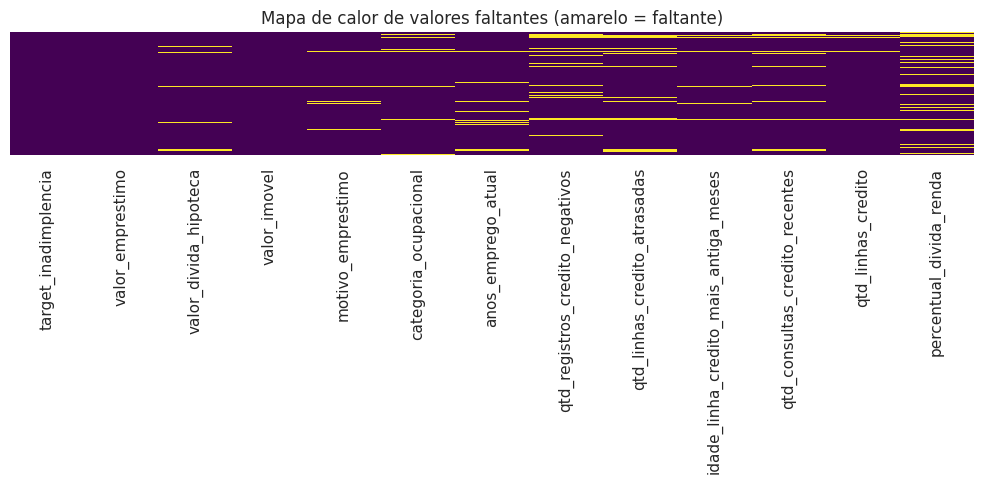

In [14]:
# Mapa de calor
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Mapa de calor de valores faltantes (amarelo = faltante)")
plt.tight_layout()
plt.show()


In [15]:
# Contagem objetiva de faltantes por coluna, para complementar o mapa de calor
print("Valores faltantes por coluna:")
print(df.isnull().sum())

print("\nPercentual de faltantes por coluna:")
print((df.isnull().mean() * 100).round(1))

Valores faltantes por coluna:
target_inadimplencia                        0
valor_emprestimo                            0
valor_divida_hipoteca                     518
valor_imovel                              112
motivo_emprestimo                         252
categoria_ocupacional                     279
anos_emprego_atual                        515
qtd_registros_credito_negativos           708
qtd_linhas_credito_atrasadas              580
idade_linha_credito_mais_antiga_meses     308
qtd_consultas_credito_recentes            510
qtd_linhas_credito                        222
percentual_divida_renda                  1267
dtype: int64

Percentual de faltantes por coluna:
target_inadimplencia                      0.0
valor_emprestimo                          0.0
valor_divida_hipoteca                     8.7
valor_imovel                              1.9
motivo_emprestimo                         4.2
categoria_ocupacional                     4.7
anos_emprego_atual                        8.6


Além de verificar o % de linhas com valores nulos, decidimos avaliar o número de colunas nulas das linhas, criando a coluna **"qtd_nulos_linha"**

In [16]:
df['qtd_nulos_linha'] = df.isnull().sum(axis=1)
df.head()

,target_inadimplencia,valor_emprestimo,valor_divida_hipoteca,valor_imovel,motivo_emprestimo,categoria_ocupacional,anos_emprego_atual,qtd_registros_credito_negativos,qtd_linhas_credito_atrasadas,idade_linha_credito_mais_antiga_meses,qtd_consultas_credito_recentes,qtd_linhas_credito,percentual_divida_renda,qtd_nulos_linha
0,1,1100.0,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN,1
1,1,1300.0,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN,1
2,1,1500.0,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN,1
3,1,1500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11
4,0,1700.0,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN,1


In [17]:
df_mais_5_nulos = df[df['qtd_nulos_linha'] > 5]
print(f'Número de linhas com mais de 5 colunas nulas: {df_mais_5_nulos.shape[0]}\n')
df_mais_5_nulos.head()

Número de linhas com mais de 5 colunas nulas: 192



,target_inadimplencia,valor_emprestimo,valor_divida_hipoteca,valor_imovel,motivo_emprestimo,categoria_ocupacional,anos_emprego_atual,qtd_registros_credito_negativos,qtd_linhas_credito_atrasadas,idade_linha_credito_mais_antiga_meses,qtd_consultas_credito_recentes,qtd_linhas_credito,percentual_divida_renda,qtd_nulos_linha
3,1,1500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11
10,1,2000.0,22608.0,NaN,NaN,NaN,18.0,NaN,NaN,NaN,NaN,NaN,NaN,9
17,1,2200.0,23030.0,NaN,NaN,NaN,19.0,NaN,NaN,NaN,NaN,NaN,3.711312,8
51,0,3100.0,NaN,70400.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10
63,1,3600.0,61584.0,61800.0,HomeImp,ProfExe,10.0,NaN,NaN,NaN,NaN,NaN,NaN,6


Resumo:
* Queremos excluir as linhas com mais de 5 colunas com valores ausentes, pois representam no mínimo 45% (6/13) dos dados faltantes;
* Encontramos 192 linhas nessa situação, o que representa um pouco mais de 3% do dataset (192/5960);
* Vamos apenas avaliar se a proporção da coluna alvo desse dataset que queremos excluir é parecida com a proporção do dataset original;

In [18]:
df_mais_5_nulos['target_inadimplencia'].value_counts(normalize=True)

,proportion
target_inadimplencia,
0,0.739583
1,0.260417


Entendemos que a proporção está similar, portanto, não vamos excluir uma proporção muito grande de inadimplentes.
Nesse sentido, **vamos retirar** do dataset de estudo essas 192 linhas.

**SUGESTÃO - JONES**
As 192 linhas excluídas possuem 26,04% de inadimplentes, percentual superior aos 19,95% da base completa. Portanto, a exclusão pode afetar proporcionalmente mais os inadimplentes. Ainda assim, optamos pela remoção porque essas linhas representam apenas 3,22% da base e possuem mais de cinco campos ausentes. Essa decisão será registrada como uma limitação da análise.

In [19]:
df = df[df['qtd_nulos_linha'] <= 5]
print(f'Depois da exclusão o DF ficou com: {df.shape[0]} linhas, {df.shape[1]} colunas.')
# 5768 linhas, 14 colunas

Depois da exclusão o DF ficou com: 5768 linhas, 14 colunas.


Em resposta a tarefa 4, segue resultado final das colunas com % de valores ausentes em ordem decrescente:

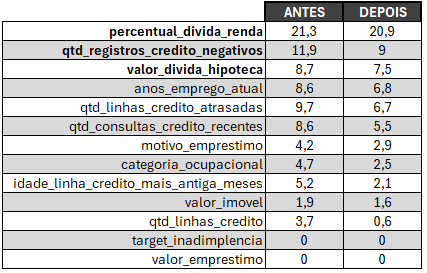

Com o dataset completo, as colunas que tinham mais valores ausentes eram:
1. percentual_divida_renda
2. qtd_registros_credito_negativos
3. qtd_linhas_credito_atrasadas

Porém, com a exclusão das linhas com mais de 5 colunas com valores asentes a ordem ficou:
1. percentual_divida_renda
2. qtd_registros_credito_negativos
3. valor_divida_hipoteca

**Tarefa 6b:** (...) e das colunas categóricas ( REASON , JOB ) com uma estratégia justificada (moda, ou categoria explícita “Não informado”).

OBS: decidimos ajustar as colunas categóricas ("motivo_emprestimo" e "categoria_ocupacional") antes de investigar uma hipótese de mecanismo de ausência (MCAR, MAR ou MNAR) da coluna com mais valores ausentes ("percentual_divida_renda").

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5768 entries, 0 to 5959
Data columns (total 14 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   target_inadimplencia                   5768 non-null   int64  
 1   valor_emprestimo                       5768 non-null   float64
 2   valor_divida_hipoteca                  5336 non-null   float64
 3   valor_imovel                           5675 non-null   float64
 4   motivo_emprestimo                      5602 non-null   object 
 5   categoria_ocupacional                  5622 non-null   object 
 6   anos_emprego_atual                     5374 non-null   float64
 7   qtd_registros_credito_negativos        5251 non-null   float64
 8   qtd_linhas_credito_atrasadas           5379 non-null   float64
 9   idade_linha_credito_mais_antiga_meses  5648 non-null   float64
 10  qtd_consultas_credito_recentes         5449 non-null   float64
 11  qtd_linha

In [21]:
contagem = df['motivo_emprestimo'].value_counts(dropna=False)
percentual = df['motivo_emprestimo'].value_counts(dropna=False, normalize=True) * 100

resumo_motivo_emprestimo = pd.DataFrame({
    'Contagem': contagem,
    'Percentual (%)': percentual.round(2)
})

resumo_motivo_emprestimo

,Contagem,Percentual (%)
motivo_emprestimo,,
DebtCon,3876,67.20
HomeImp,1726,29.92
NaN,166,2.88


In [22]:
contagem = df['categoria_ocupacional'].value_counts(dropna=False)
percentual = df['categoria_ocupacional'].value_counts(dropna=False, normalize=True) * 100

resumo_categoria_ocupacional = pd.DataFrame({
    'Contagem': contagem,
    'Percentual (%)': percentual.round(2)
})

resumo_categoria_ocupacional

,Contagem,Percentual (%)
categoria_ocupacional,,
Other,2360,40.92
ProfExe,1268,21.98
Office,942,16.33
Mgr,752,13.04
Self,191,3.31
NaN,146,2.53
Sales,109,1.89


### **Decisão sobre a imputação dos dados categóricos:**
* motivo_emprestimo: Vai pela moda, uma vez que seu volume é bem baixo em comparação com o dataset;
* categoria_ocupacional: por ser uma categoria genérica iremos incluir os valores ausentes na categoria "Other". Por acaso essa categoria também é a moda.


In [23]:
moda_motivo_emprestimo = df['motivo_emprestimo'].mode()[0]
df['motivo_emprestimo'] = df['motivo_emprestimo'].fillna(moda_motivo_emprestimo)

valor_fixo_categoria_ocupacional = 'Other'
df['categoria_ocupacional'] = df['categoria_ocupacional'].fillna(valor_fixo_categoria_ocupacional)

print(f'Valores ausentes de "motivo_emprestimo" foram preenchidos com {moda_motivo_emprestimo}, já os de "categoria_ocupacional" com {valor_fixo_categoria_ocupacional}')

Valores ausentes de "motivo_emprestimo" foram preenchidos com DebtCon, já os de "categoria_ocupacional" com Other


In [24]:
contagem = df['motivo_emprestimo'].value_counts(dropna=False)
percentual = df['motivo_emprestimo'].value_counts(dropna=False, normalize=True) * 100

resumo_motivo_emprestimo = pd.DataFrame({
    'Contagem': contagem,
    'Percentual (%)': percentual.round(2)
})

resumo_motivo_emprestimo

,Contagem,Percentual (%)
motivo_emprestimo,,
DebtCon,4042,70.08
HomeImp,1726,29.92


In [25]:
contagem = df['categoria_ocupacional'].value_counts(dropna=False)
percentual = df['categoria_ocupacional'].value_counts(dropna=False, normalize=True) * 100

resumo_categoria_ocupacional = pd.DataFrame({
    'Contagem': contagem,
    'Percentual (%)': percentual.round(2)
})

resumo_categoria_ocupacional

,Contagem,Percentual (%)
categoria_ocupacional,,
Other,2506,43.45
ProfExe,1268,21.98
Office,942,16.33
Mgr,752,13.04
Self,191,3.31
Sales,109,1.89


**Tarefa 5:** Para a coluna com mais faltantes, investiguem uma hipótese de mecanismo de ausência (MCAR, MAR ou MNAR):
* A taxa de faltantes varia entre grupos de REASON ("motivo_emprestimo") ou JOB ("categoria_ocupacional") ?

Documentem a evidência a favor ou contra cada hipótese — não existe
resposta única “correta” aqui, o que importa é o raciocínio.

In [26]:
print("Taxa de faltantes em 'percentual_divida_renda', por motivo de empréstimo:")
print(taxa_faltante_por_grupo(df, 'motivo_emprestimo', 'percentual_divida_renda'))
# DebtCon (consolidação de dívida) e HomeImp (reforma/melhoria residencial)

Taxa de faltantes em 'percentual_divida_renda', por motivo de empréstimo:
motivo_emprestimo
DebtCon    0.2031
HomeImp    0.2219
Name: percentual_divida_renda, dtype: float64


Os resultados estão muito próximos entre as duas categorias, o que evidencia que a variável "percentual_divida_renda" não tem uma associação forte com a variável "motivo_emprestimo"

**SUGESTÃO - JONES**
As diferenças nas taxas de ausência entre as categorias ocupacionais enfraquecem a hipótese de MCAR e apresentam indícios compatíveis com MAR condicionado à categoria ocupacional. Entretanto, essa análise não permite descartar completamente um mecanismo MNAR.

In [27]:
#Verificando as taxas faltantes por "categoria_ocupacional"
print("Taxa de faltantes em 'percentual_divida_renda', por categoria ocupacional:")
print(taxa_faltante_por_grupo(df, 'categoria_ocupacional', 'percentual_divida_renda'))

Taxa de faltantes em 'percentual_divida_renda', por categoria ocupacional:
categoria_ocupacional
Mgr        0.2340
Office     0.1645
Other      0.2195
ProfExe    0.1924
Sales      0.2752
Self       0.2565
Name: percentual_divida_renda, dtype: float64


Há uma maior amplitude de **cerca 11%** entre o menor e maior percentual, levando a ter mais indícios de MAR para a categoria "categoria_ocupacional".

* Mgr — Manager (gerente)
* Office — funções administrativas/escritório
* Other — outras categorias não especificadas
* ProfExe — Professional/Executive (profissional/executivo)
* Sales — vendas
* Self — Self-employed (autônomo)

Olhando para os dados, faz sentido quem trabalhar com vendas ou ser autônomo não ter renda fixa e, por sua vez, deixar de existir o dado de renda levando a ausência da variável "percentual_divida_renda".

AVALIAR SE NÃO SE ENCAIXA MAIS COM O MCAR - AUSENCIA DE DADOS POR ALEATORIEDADE

In [28]:
# Guarda os valores originais não-nulos antes de imputar
mask_nao_nulo = df["percentual_divida_renda"].notnull()
valores_originais = df.loc[mask_nao_nulo, "percentual_divida_renda"].copy()

# Roda a imputação
df = imputar_percentual_divida_renda(df)

# Compara as colunas com valores não nulos com o DF final para verificar se o KNN mudou algum dados existente
diferenca = (df.loc[mask_nao_nulo, "percentual_divida_renda"] - valores_originais).abs()
print(diferenca.describe())

count    4.564000e+03
mean     3.772910e-17
std      5.105778e-16
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.842171e-14
Name: percentual_divida_renda, dtype: float64


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5768 entries, 0 to 5959
Data columns (total 14 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   target_inadimplencia                   5768 non-null   int64  
 1   valor_emprestimo                       5768 non-null   float64
 2   valor_divida_hipoteca                  5336 non-null   float64
 3   valor_imovel                           5675 non-null   float64
 4   motivo_emprestimo                      5768 non-null   object 
 5   categoria_ocupacional                  5768 non-null   object 
 6   anos_emprego_atual                     5374 non-null   float64
 7   qtd_registros_credito_negativos        5251 non-null   float64
 8   qtd_linhas_credito_atrasadas           5379 non-null   float64
 9   idade_linha_credito_mais_antiga_meses  5648 non-null   float64
 10  qtd_consultas_credito_recentes         5449 non-null   float64
 11  qtd_linha

**Dados da coluna "percentual_divida_renda" inseridos com sucesso com o método KNN. E avaliado que esse processo não alterou os dados que já existiam.**

**Tarefa 6a:** Tratem os faltantes das colunas numéricas (decidam e justifiquem: mediana, mediana por grupo, ou KNNImputer - como praticamos na Aula 3).

Ficou definido que:
* Valores abaixo de 7% será imputado pela mediana simples;
* Valores superiores a 7% vale a pena ter estudo, tal qual feito para a variável "percentual_divida_renda";

In [30]:
print("\nPercentual de faltantes por coluna:")
print((df.isnull().mean() * 100).round(1))


Percentual de faltantes por coluna:
target_inadimplencia                     0.0
valor_emprestimo                         0.0
valor_divida_hipoteca                    7.5
valor_imovel                             1.6
motivo_emprestimo                        0.0
categoria_ocupacional                    0.0
anos_emprego_atual                       6.8
qtd_registros_credito_negativos          9.0
qtd_linhas_credito_atrasadas             6.7
idade_linha_credito_mais_antiga_meses    2.1
qtd_consultas_credito_recentes           5.5
qtd_linhas_credito                       0.6
percentual_divida_renda                  0.0
qtd_nulos_linha                          0.0
dtype: float64


In [31]:
print("Taxa de faltantes em 'valor_divida_hipoteca' por 'motivo_emprestimo':")
print(taxa_faltante_por_grupo(df, 'motivo_emprestimo', 'valor_divida_hipoteca'))

Taxa de faltantes em 'valor_divida_hipoteca' por 'motivo_emprestimo':
motivo_emprestimo
DebtCon    0.0505
HomeImp    0.1321
Name: valor_divida_hipoteca, dtype: float64


In [32]:
print("Taxa de faltantes em 'valor_divida_hipoteca' por 'categoria_ocupacional':")
print(taxa_faltante_por_grupo(df, 'categoria_ocupacional', 'valor_divida_hipoteca'))

Taxa de faltantes em 'valor_divida_hipoteca' por 'categoria_ocupacional':
categoria_ocupacional
Mgr        0.0372
Office     0.0637
Other      0.1217
ProfExe    0.0126
Sales      0.0917
Self       0.0681
Name: valor_divida_hipoteca, dtype: float64


In [33]:
# Mediana de valor_divida_hipoteca por categoria_ocupacional
mediana_por_categoria = df.groupby('categoria_ocupacional')['valor_divida_hipoteca'].median()
print("Mediana de 'valor_divida_hipoteca' por 'categoria_ocupacional':")
print(mediana_por_categoria)

print()

# Mediana de valor_divida_hipoteca por motivo_emprestimo
mediana_por_motivo = df.groupby('motivo_emprestimo')['valor_divida_hipoteca'].median()
print("Mediana de 'valor_divida_hipoteca' por 'motivo_emprestimo':")
print(mediana_por_motivo)

Mediana de 'valor_divida_hipoteca' por 'categoria_ocupacional':
categoria_ocupacional
Mgr        76803.0
Office     62996.0
Other      54641.0
ProfExe    82921.0
Sales      71800.0
Self       87899.0
Name: valor_divida_hipoteca, dtype: float64

Mediana de 'valor_divida_hipoteca' por 'motivo_emprestimo':
motivo_emprestimo
DebtCon    66496.5
HomeImp    62833.0
Name: valor_divida_hipoteca, dtype: float64


Essa variação sugere que os dados não estão faltando aleatoriamente, aparentemente não parece ser MCAR. Parece que quem não informa a hipoteca tende a se concentrar em certos perfis (ex: "Other" e "HomeImp"):

* Por motivo_emprestimo: HomeImp tem quase o dobro de faltantes (13,2%) comparado a DebtCon (5,1%)
* Por categoria_ocupacional: variação ainda maior — de 1,3% (ProfExe) a 12,2% (Other)

**Decisão final é usar mediana por grupo da variável 'categoria_ocupacional' para imputar dados em 'valor_divida_hipoteca', pois a categoria possui maior variabilidade da mediana em seus grupos.**

In [34]:
print("Taxa de faltantes em 'qtd_registros_credito_negativos' por 'motivo_emprestimo':")
print(taxa_faltante_por_grupo(df, 'motivo_emprestimo', 'qtd_registros_credito_negativos'))

Taxa de faltantes em 'qtd_registros_credito_negativos' por 'motivo_emprestimo':
motivo_emprestimo
DebtCon    0.1000
HomeImp    0.0655
Name: qtd_registros_credito_negativos, dtype: float64


In [35]:
print("Taxa de faltantes em 'qtd_registros_credito_negativos' por 'categoria_ocupacional':")
print(taxa_faltante_por_grupo(df, 'categoria_ocupacional', 'qtd_registros_credito_negativos'))

Taxa de faltantes em 'qtd_registros_credito_negativos' por 'categoria_ocupacional':
categoria_ocupacional
Mgr        0.1250
Office     0.1093
Other      0.0918
ProfExe    0.0599
Sales      0.0917
Self       0.0209
Name: qtd_registros_credito_negativos, dtype: float64


In [36]:
# Mediana de qtd_registros_credito_negativos por categoria_ocupacional
mediana_por_categoria = df.groupby('categoria_ocupacional')['qtd_registros_credito_negativos'].median()
print("Mediana de 'qtd_registros_credito_negativos' por categoria_ocupacional:")
print(mediana_por_categoria)

print()

# Mediana de qtd_registros_credito_negativos por motivo_emprestimo
mediana_por_motivo = df.groupby('motivo_emprestimo')['qtd_registros_credito_negativos'].median()
print("Mediana de 'qtd_registros_credito_negativos' por motivo_emprestimo:")
print(mediana_por_motivo)

Mediana de 'qtd_registros_credito_negativos' por categoria_ocupacional:
categoria_ocupacional
Mgr        0.0
Office     0.0
Other      0.0
ProfExe    0.0
Sales      0.0
Self       0.0
Name: qtd_registros_credito_negativos, dtype: float64

Mediana de 'qtd_registros_credito_negativos' por motivo_emprestimo:
motivo_emprestimo
DebtCon    0.0
HomeImp    0.0
Name: qtd_registros_credito_negativos, dtype: float64


**Há variação significativa nos grupos, porém, a mediana em todos os grupos é a mesma. Nesse sentido, podemos imputar com a mediana geral.**

In [37]:
# Imputação com mediana
colunas_para_imputar = [
    "valor_imovel",
    "anos_emprego_atual",
    "qtd_linhas_credito_atrasadas",
    "idade_linha_credito_mais_antiga_meses",
    "qtd_consultas_credito_recentes",
    "qtd_linhas_credito",
    "qtd_registros_credito_negativos"
]

for col in colunas_para_imputar:
    df[col] = df[col].fillna(df[col].median())

In [38]:
# Imputação por mediana de grupo
# Mediana para dívida de hipoteca por categora ocupacional
mediana_valor_divida_hipoteca_por_categoria_ocupacional = df.groupby("categoria_ocupacional")["valor_divida_hipoteca"].transform("median")
df["valor_divida_hipoteca"] = df["valor_divida_hipoteca"].fillna(mediana_valor_divida_hipoteca_por_categoria_ocupacional)


In [39]:
print("\nPercentual de faltantes por coluna:")
print((df.isnull().mean() * 100).round(1))


Percentual de faltantes por coluna:
target_inadimplencia                     0.0
valor_emprestimo                         0.0
valor_divida_hipoteca                    0.0
valor_imovel                             0.0
motivo_emprestimo                        0.0
categoria_ocupacional                    0.0
anos_emprego_atual                       0.0
qtd_registros_credito_negativos          0.0
qtd_linhas_credito_atrasadas             0.0
idade_linha_credito_mais_antiga_meses    0.0
qtd_consultas_credito_recentes           0.0
qtd_linhas_credito                       0.0
percentual_divida_renda                  0.0
qtd_nulos_linha                          0.0
dtype: float64


In [40]:
# Depois de todos os dados imputados, podemos alterar o tipo da variável para inteiro
colunas_para_alterar_int = [
    "qtd_registros_credito_negativos",
    "qtd_linhas_credito_atrasadas",
    "qtd_consultas_credito_recentes",
    "qtd_linhas_credito"
]

for col in colunas_para_alterar_int:
    df[col] = df[col].astype('int64')

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5768 entries, 0 to 5959
Data columns (total 14 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   target_inadimplencia                   5768 non-null   int64  
 1   valor_emprestimo                       5768 non-null   float64
 2   valor_divida_hipoteca                  5768 non-null   float64
 3   valor_imovel                           5768 non-null   float64
 4   motivo_emprestimo                      5768 non-null   object 
 5   categoria_ocupacional                  5768 non-null   object 
 6   anos_emprego_atual                     5768 non-null   float64
 7   qtd_registros_credito_negativos        5768 non-null   int64  
 8   qtd_linhas_credito_atrasadas           5768 non-null   int64  
 9   idade_linha_credito_mais_antiga_meses  5768 non-null   float64
 10  qtd_consultas_credito_recentes         5768 non-null   int64  
 11  qtd_linha

# **Bloco 3 - Análise Univariada e Outliers**

**Tarefa 8:**
1. Calculem .describe()
2. Para as 3 variáveis contínuas que vocês julgarem mais relevantes para o negócio, calculem skewness e kurtosis, com histograma + KDE e boxplot.

In [41]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
target_inadimplencia,5768.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00
valor_emprestimo,5768.0,18783.24,11286.37,1100.00,11200.00,16500.00,23500.00,89900.00
valor_divida_hipoteca,5768.0,72886.78,43206.05,2063.00,48002.25,63028.50,89025.25,399550.00
valor_imovel,5768.0,102078.62,57378.57,8000.00,66543.50,89720.00,119393.25,855909.00
anos_emprego_atual,5768.0,8.80,7.35,0.00,3.00,7.00,12.15,41.00
qtd_registros_credito_negativos,5768.0,0.23,0.81,0.00,0.00,0.00,0.00,10.00
qtd_linhas_credito_atrasadas,5768.0,0.42,1.09,0.00,0.00,0.00,0.00,15.00
idade_linha_credito_mais_antiga_meses,5768.0,179.62,84.89,0.00,116.10,173.47,229.52,1168.23
qtd_consultas_credito_recentes,5768.0,1.18,1.68,0.00,0.00,1.00,2.00,17.00
qtd_linhas_credito,5768.0,21.30,10.11,0.00,15.00,20.00,26.00,71.00


Foram selecionadas três variáveis contínuas relevantes para o negócio:

Valor do empréstimo: representa o valor financeiro exposto ao risco. Empréstimos maiores podem produzir perdas maiores em caso de inadimplência.
Percentual dívida/renda: representa quanto da renda do cliente está comprometida com dívidas, sendo um indicador importante da capacidade de pagamento.
Idade da linha de crédito mais antiga: representa o tempo de experiência do cliente com crédito. Um histórico mais longo pode fornecer mais informações sobre seu comportamento financeiro.


Skewness de valor_emprestimo: 2.02
Kurtosis (excesso) de valor_emprestimo: 6.83


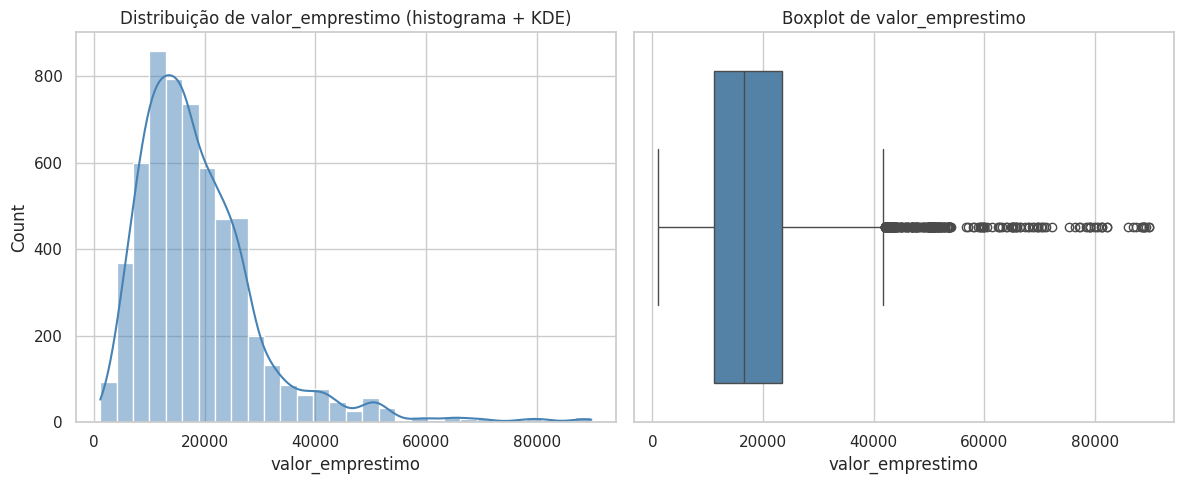


Skewness de idade_linha_credito_mais_antiga_meses: 1.36
Kurtosis (excesso) de idade_linha_credito_mais_antiga_meses: 7.84


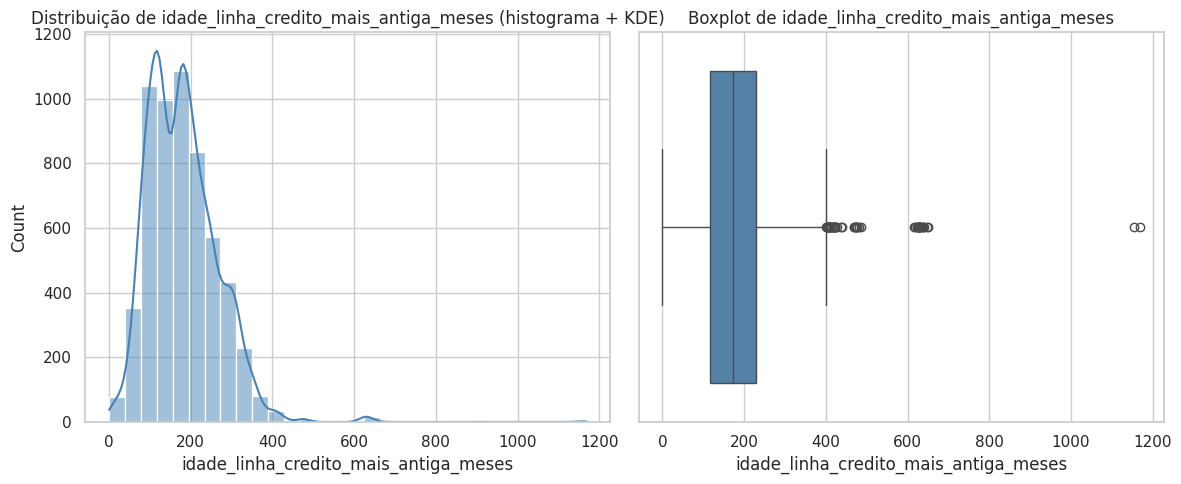


Skewness de percentual_divida_renda: 2.71
Kurtosis (excesso) de percentual_divida_renda: 50.48


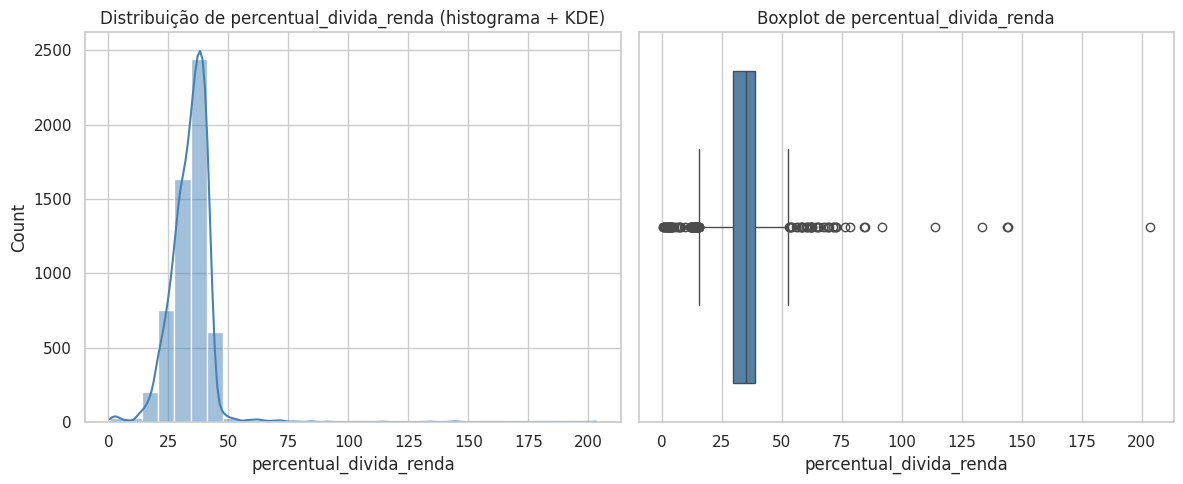

In [42]:
# valor_emprestimo: skewness e kurtosis, com histograma + KDE e boxplot.
colunas = ["valor_emprestimo", "idade_linha_credito_mais_antiga_meses", "percentual_divida_renda"]

for col in colunas:
    skew_kurt(df, col)
    plot_dist_boxplot(df, col)
    print()

Das variáveis escolhidas, temos:
* Skewness: Maior que zeros em todas, evidenciando uma cauda mais longa a direita;
* Kurtosis: Todas maior que zero, porém, um destaque especial para **percentual_divida_renda** que com um valor de 50 evidencia um forte peso a valores extremos, quando comparada as outras duas que possuem valores menores que 10;
* Os resultados de Skewness e Kurtosis puderam ser melhor visualizados pelos gráficos gerados;

Skewness de valor_divida_hipoteca: 1.92
Kurtosis (excesso) de valor_divida_hipoteca: 7.16


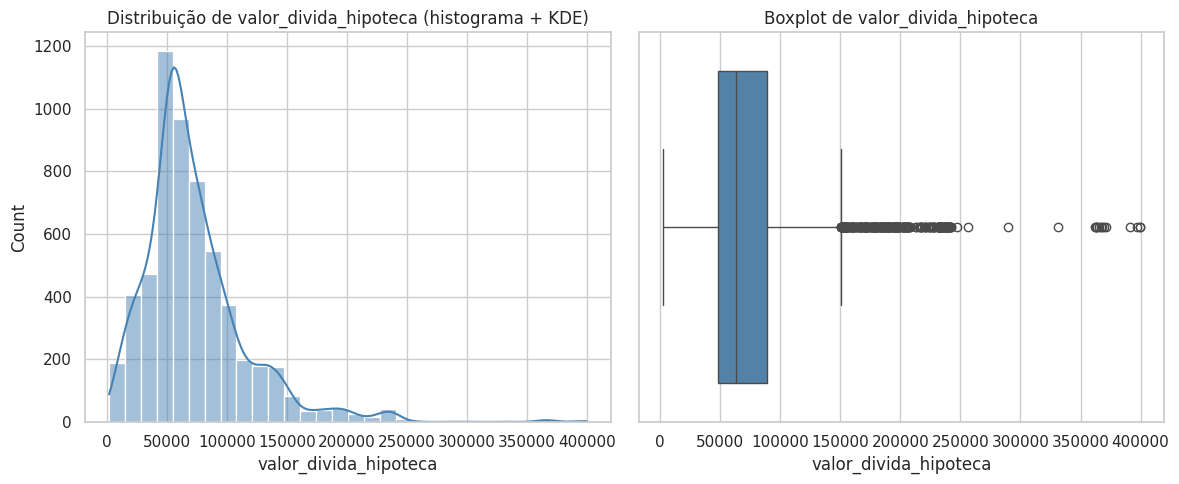


Skewness de valor_imovel: 3.09
Kurtosis (excesso) de valor_imovel: 24.65


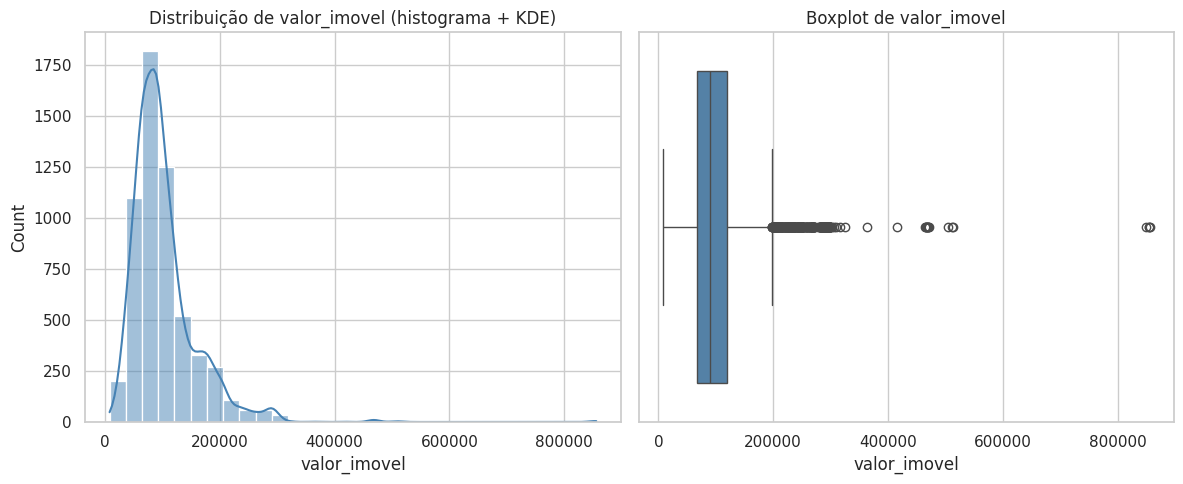


Skewness de anos_emprego_atual: 1.07
Kurtosis (excesso) de anos_emprego_atual: 0.65


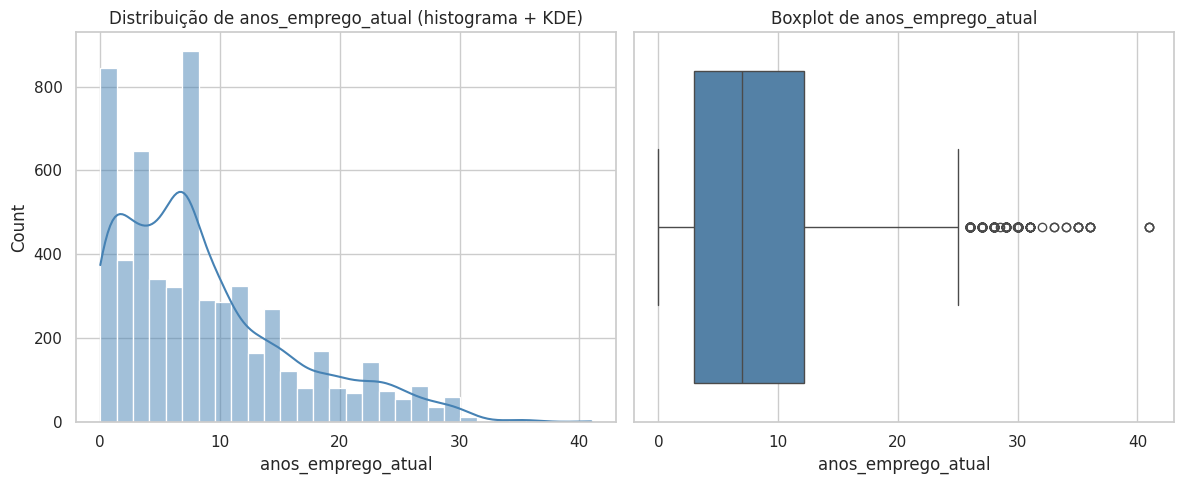

In [43]:
# Análise das demais variáveis contínuas, que não foram escolhidas (apenas por curiosidade):
colunas = ["valor_divida_hipoteca", "valor_imovel", "anos_emprego_atual", ]

for col in colunas:
    skew_kurt(df, col)
    plot_dist_boxplot(df, col)
    print()

**Tarefa 9:**
1. Apliquem a regra do IQR e o critério de Z-Score em DEBTINC/"percentual_divida_renda" (razão dívida/renda).
2. Os dois critérios encontram a mesma quantidade de outliers?
3. Existe algum limite de regra de negócio plausível para essa variável (pensem: que valor de DEBTINC já seria, por definição, implausível)?

In [44]:
# regra do IQR
df_outliers_iqr = outliers_iqr(df, 'percentual_divida_renda')

Q1 = 29.7 | Q3 = 39.0 | IQR = 9.3
Limite inferior = 15.7 | Limite superior = 53.0
Quantidade de outliers pela regra do IQR: 120



In [45]:
df_outliers_iqr.head()

,target_inadimplencia,valor_emprestimo,valor_divida_hipoteca,valor_imovel,motivo_emprestimo,categoria_ocupacional,anos_emprego_atual,qtd_registros_credito_negativos,qtd_linhas_credito_atrasadas,idade_linha_credito_mais_antiga_meses,qtd_consultas_credito_recentes,qtd_linhas_credito,percentual_divida_renda,qtd_nulos_linha
57,1,3200.0,23159.0,89720.0,HomeImp,Mgr,20.0,0,2,117.805748,0,9,0.524499,2
92,0,4000.0,54641.0,45760.0,HomeImp,Other,0.0,0,0,173.466667,0,0,13.293199,4
118,0,4500.0,54641.0,49044.0,HomeImp,Other,0.0,0,0,173.466667,0,0,11.652739,3
216,1,5200.0,40564.0,39527.0,HomeImp,Other,0.0,0,0,157.771036,1,13,72.670433,0
220,0,5300.0,54641.0,49396.0,HomeImp,Other,0.0,0,0,173.466667,0,0,12.043671,3


In [46]:
df_outliers_zscore = outliers_zscore(df, 'percentual_divida_renda')

Quantidade de outliers pelo critério de Z-Score (|Z| > 3): 68


Os critérios não encontraram a mesma quantidade de outliers:

O IQR identificou 120 registros, com limites de 15,65% e 52,98%.
O Z-Score identificou 68 registros, com limites aproximados de 9,55% e 58,58%.
Os 68 casos do Z-Score também foram identificados pelo IQR; portanto, o IQR encontrou 52 casos adicionais.
A diferença é esperada. O IQR usa quartis e é mais resistente à assimetria. O Z-Score depende da média e do desvio-padrão; como a distribuição tem uma cauda direita extrema, chegando a 203,31%, o desvio-padrão aumenta e o critério fica menos sensível.

Quanto à regra de negócio, uma razão dívida/renda negativa seria impossível. Um valor acima de 100% não é matematicamente impossível, mas indica obrigações de dívida superiores à renda declarada e é operacionalmente crítico ou possivelmente inconsistente. Por isso, adotamos 100% como limite de validação e revisão, não como justificativa automática para excluir o cliente. Foram encontrados 5 registros acima desse valor. Os 74 valores abaixo do limite inferior do IQR foram mantidos, pois uma razão dívida/renda baixa é perfeitamente plausível.

**Tarefa 10:** Escolham um tratamento para os outliers encontrado (winsorization, transformação logarítmica, ou exclusão justificada) e apliquem.

Foi escolhida a winsorização unilateral pelo limite de negócio de 100%. Ela preserva todas as linhas e a informação de alto risco, mas impede que cinco valores extremos dominem médias, correlações e gráficos. A cauda inferior não será alterada, pois valores baixos de dívida/renda são válidos.

Registros winsorizados: 5


,Antes,Depois
Mínimo,0.52,0.52
Máximo,203.31,100.00
Média,34.07,34.02
Desvio-padrão,8.17,7.65
Skewness,2.71,0.39
Kurtosis,50.52,8.00


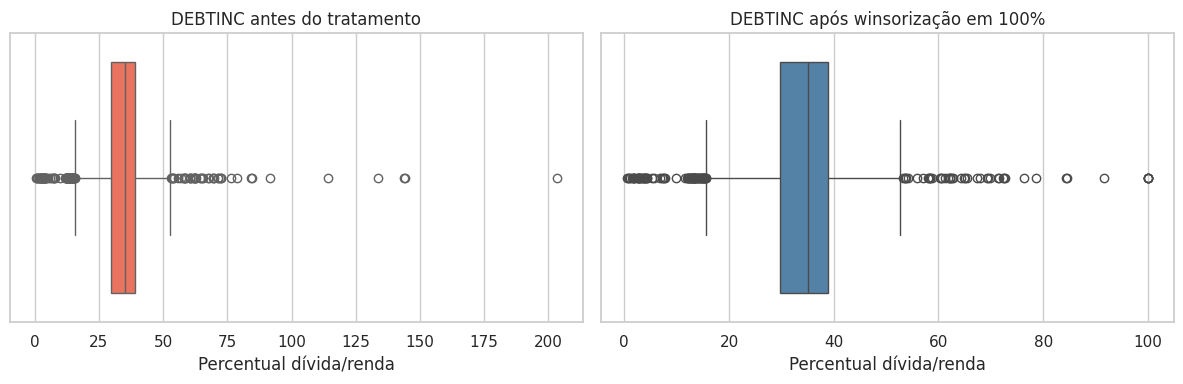

In [47]:
# O DataFrame original tratado até a Tarefa 9 permanece em `df`.
# As análises seguintes usam uma cópia com o tratamento de outliers.
df_tratado = df.copy()
coluna_dti = 'percentual_divida_renda'
antes = df_tratado[coluna_dti].copy()
df_tratado[coluna_dti] = df_tratado[coluna_dti].clip(lower=0, upper=100)
depois = df_tratado[coluna_dti]

comparacao_tratamento = pd.DataFrame(
    {
        "Antes": [antes.min(), antes.max(), antes.mean(), antes.std(), antes.skew(), antes.kurt()],
        "Depois": [depois.min(), depois.max(), depois.mean(), depois.std(), depois.skew(), depois.kurt()],
    },
    index=["Mínimo", "Máximo", "Média", "Desvio-padrão", "Skewness", "Kurtosis"],
)

print(f"Registros winsorizados: {(antes != depois).sum()}")
display(comparacao_tratamento.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=antes, ax=axes[0], color="tomato")
axes[0].set_title("DEBTINC antes do tratamento")
axes[0].set_xlabel("Percentual dívida/renda")

sns.boxplot(x=depois, ax=axes[1], color="steelblue")
axes[1].set_title("DEBTINC após winsorização em 100%")
axes[1].set_xlabel("Percentual dívida/renda")

plt.tight_layout()
plt.show()

A winsorização alterou somente 5 de 5.768 registros (0,09%). O máximo caiu de 203,31% para 100%, a assimetria caiu de aproximadamente 2,71 para 0,39 e nenhuma observação foi removida. Em um processo real, esses cinco casos também deveriam ser encaminhados para conferência da renda e das obrigações informadas.

# **Bloco 4 - Bivariada, Multivariada e Feature Engineering:**

**Tarefa 11:**
1. Calculem a correlação (Pearson e Spearman) entre as variáveis numéricas e o alvo BAD.
2. Qual variável está mais associada à inadimplência?
3. Isso já é prova de causalidade?

**Tarefa 12:** Comparem DEBTINC (ou outra variável contínua à escolha) entre os grupos BAD == 0 e BAD == 1 com boxplot ou violin plot.

**Tarefa 13:** Cruzem REASON x JOB com pd.crosstab() e testem associação com chi2_contingency().

In [50]:
tabela_contingencia = pd.crosstab(df_tratado['motivo_emprestimo'], df_tratado['categoria_ocupacional'])
print("Tabela de contingência (Motivo Empréstimo x Categoria Ocupacional):")
display(tabela_contingencia)

chi2, p_valor, graus_liberdade, valores_esperados = stats.chi2_contingency(tabela_contingencia)

print(f"p-valor: {p_valor:.4f}")

Tabela de contingência (Motivo Empréstimo x Categoria Ocupacional):


categoria_ocupacional,Mgr,Office,Other,ProfExe,Sales,Self
motivo_emprestimo,,,,,,
DebtCon,582,643,1774,868,97,78
HomeImp,170,299,732,400,12,113


p-valor: 0.0000


O teste confirmou `p < 0,5` que o motivo do empréstimo está relacionado a categoria ocupacional do cliente. Profissionais autônomos, por exemplo, demonstram uma tendência significativa maior a buscar crédito para reformas residenciais em comparaçõa com profissionais de vendas, que buscam prioritariamente a consolidaçãp de dívidas.

**Tarefa 14:** Feature engineering (adaptado, já que o HMEQ não tem coluna de
data): criem pelo menos uma variável nova a partir das existentes — por exemplo, uma faixa categórica de DEBTINC com pd.cut() , ou uma razão nova como LOAN / VALUE (quanto do valor do imóvel o empréstimo
representa). Justifiquem por que essa variável poderia ajudar a explicar BAD .

# **Bloco 5 - EDA Automatizada e Storytelling**

**Tarefa 15:**
1. Rodem ydata-profiling ou sweetviz sobre a base tratada e comparem com o que vocês encontraram manualmente.
2. O relatório automático revelou algo que vocês não tinham notado?

**Tarefa 16:** Escrevam, em texto, 3 insights no formato Achado / Evidência /Ação Recomendada, como se fossem apresentar para a diretoria de risco do banco (sem jargão técnico na parte do “achado” e da “ação”).

O gráfico revela um comportamento não-linear do risco de crédito, destacando que a taxa de inadimplência atinge seu ápice em aproximadamente 27% na faixa acima de 100%. O risco oscila nas faixas iniciais e apresenta uma queda acentuada para cerca de 17% na janela de 75%–100%, um fenômeno comum no mercado financeiro que reflete critérios de aprovação muito mais rigorosos pelo banco ou um esforço extremo do cliente para salvar o patrimônio antes do colapso da dívida. Essa oscilação de tendências (subida, queda e explosão de risco) reforça que algoritmos baseados em árvores de decisão, como Random Forest ou XGBoost, serão os mais eficientes para capturar esse padrão complexo no seu modelo preditivo.